# Extração de características das imagens**Entrada:** `data/raw/Airbnb/photos/*.jpg` — 294 fotos de capa do piloto**Saídas:**- `data/processed/Airbnb/image_features.csv` — uma linha por listing- `data/processed/Airbnb/clip_embeddings.npz` — embeddings 512-d- `data/processed/Airbnb/clip_prompts.json` — prompts usados (proveniência)Notebook de **construção**, não de análise: roda uma vez e grava. Os notebooks`image_clusters.ipynb` (objetivo 2) e `image_review_match.ipynb` (objetivo 3)apenas consomem essas saídas.Três blocos de features:| bloco | nº | o que é ||---|---|---|| low-level | 13 | qualidade fotográfica — brilho, contraste, nitidez, cor. Sem modelo. || CLIP aspectos | 6 | `img_<aspecto>` zero-shot: limpeza, espaço, luz, decoração, vista, lazer || CLIP cômodo | 7 + 2 | que cômodo a foto mostra — endereça o problema de quarto privativo || embeddings | 512 | vetor bruto, insumo do clustering |**Sobre o bloco de cômodo:** 90 dos 294 anúncios são `Private room`, e nesses acapa costuma mostrar a área comum da casa, não o quarto alugado (ver `100549.jpg`).Classificar o cômodo permite filtrar ou controlar por isso no objetivo 3.

## 1. Setup

In [1]:
import glob
import json
import os
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image, ImageFilter

IMG_DIR = Path("../data/raw/Airbnb/photos")
PROC    = Path("../data/processed/Airbnb")
OUT_CSV = PROC / "image_features.csv"
OUT_EMB = PROC / "clip_embeddings.npz"
OUT_PRM = PROC / "clip_prompts.json"

BATCH = 32
CLIP_MODEL = "openai/clip-vit-base-patch32"

PROC.mkdir(parents=True, exist_ok=True)

paths = sorted(IMG_DIR.glob("*.jpg"), key=lambda p: int(p.stem))
print(f"fotos encontradas: {len(paths)}")
print(f"ids: {paths[0].stem} ... {paths[-1].stem}")

fotos encontradas: 294
ids: 4917 ... 6603502


## 2. Features low-levelQualidade fotográfica pura: sem modelo, sem GPU, segundos para as 294.

In [2]:
def colorfulness(a: np.ndarray) -> float:
    '''Métrica de Hasler & Süsstrunk (2003).'''
    r, g, b = a[..., 0], a[..., 1], a[..., 2]
    rg, yb = r - g, 0.5 * (r + g) - b
    return float(np.hypot(rg.std(), yb.std()) + 0.3 * np.hypot(rg.mean(), yb.mean()))


def lowlevel_one(path: Path) -> dict:
    im = Image.open(path).convert("RGB")
    w, h = im.size
    a    = np.asarray(im, dtype=np.float32)
    gray = a @ np.array([0.299, 0.587, 0.114], dtype=np.float32)
    hsv  = np.asarray(im.convert("HSV"), dtype=np.float32)
    edges = np.asarray(im.convert("L").filter(ImageFilter.FIND_EDGES), dtype=np.float32)
    lap   = np.asarray(
        im.convert("L").filter(ImageFilter.Kernel((3, 3), [0, 1, 0, 1, -4, 1, 0, 1, 0], scale=1)),
        dtype=np.float32,
    )
    return {
        "img_width":        w,
        "img_height":       h,
        "img_aspect":       w / h,
        "img_megapixels":   w * h / 1e6,
        "img_brightness":   float(gray.mean() / 255),
        "img_contrast":     float(gray.std() / 255),
        "img_saturation":   float(hsv[..., 1].mean() / 255),
        "img_colorfulness": colorfulness(a),
        "img_sharpness":    float(lap.var()),        # variância do Laplaciano
        "img_edge_density": float((edges > 40).mean()),
        "img_dark_share":   float((gray < 40).mean()),
        "img_blown_share":  float((gray > 240).mean()),
        "img_warmth":       float((a[..., 0] - a[..., 2]).mean() / 255),
    }

In [3]:
rows, falhas = [], []
for p in paths:
    try:
        rows.append({"id": int(p.stem), **lowlevel_one(p)})
    except Exception as e:
        falhas.append((p.name, str(e)))

low = pd.DataFrame(rows)
print(f"low-level: {low.shape[0]} imagens x {low.shape[1] - 1} features")
print(f"falhas: {len(falhas)}", falhas[:5] if falhas else "")
low.describe().T[["mean", "std", "min", "max"]].round(3)

low-level: 294 imagens x 13 features
falhas: 0 


,mean,std,min,max
id,3025335.901,1876712.077,4917.000,6603502.000
img_width,490.925,57.284,231.000,512.000
img_height,373.588,61.542,230.000,512.000
img_aspect,1.362,0.298,0.451,2.226
img_megapixels,0.181,0.019,0.104,0.262
img_brightness,0.541,0.110,0.252,0.834
img_contrast,0.229,0.040,0.112,0.401
img_saturation,0.261,0.110,0.000,0.640
img_colorfulness,38.890,16.360,0.000,96.581
img_sharpness,655.288,313.962,143.617,2165.280


## 3. CLIP — aspectos e cômodoDois usos do mesmo forward pass:**Aspectos** — cada aspecto é um *eixo* definido por um par de prompts (polo positivoe negativo). A feature é a **margem de similaridade de cosseno**: `cos(img, pos) − cos(img, neg)`.> Por que a margem bruta e não a probabilidade softmax: os logits do CLIP vêm> multiplicados por `logit_scale ≈ 100`, então `softmax` satura em 0 ou 1 e> esmaga a variação no meio da distribuição — justamente onde está a informação> para correlação. A margem é transformação **monotônica** da softmax, então a> correlação de Spearman é idêntica, mas sem perda por saturação.**Cômodo** — classificação multiclasse normal (softmax sobre as 7 classes),guardando a classe vencedora e a confiança.

In [4]:
# Prompts SEM âncora de cena ("interior", "room"): a versão anterior ancorava
# os dois polos em interiores, então foto de piscina não casava com nenhum dos
# dois e a margem virava ruído -- img_decor acabou correlacionando +0,53 com
# "é área de lazer". Ver outputs/clip_sanity_check_v1.png.
ASPECTS = {
    "cleanliness": (
        ["a clean, spotless, well maintained place", "a tidy, orderly, freshly cleaned place"],
        ["a dirty, messy, cluttered place", "a neglected, run down, grimy place"],
    ),
    "space": (
        ["a large, open, spacious place with plenty of room"],
        ["a small, cramped, narrow place with no room"],
    ),
    "light": (
        ["a bright place full of natural daylight", "a sunlit place with lots of light"],
        ["a dark, dim, poorly lit place", "a gloomy place with no light"],
    ),
    "decor": (
        ["a stylish, modern, recently renovated place", "a tastefully decorated, well designed place"],
        ["an outdated, worn out, shabby place", "a plain, cheaply furnished, dated place"],
    ),
    "view": (
        ["a wide open view over the city or the landscape"],
        ["a closed place with no view, surrounded by walls"],
    ),
    "leisure": (
        ["a swimming pool, gym or rooftop leisure area"],
        ["a place with no leisure or recreation facilities"],
    ),
}

ROOMS = {
    "bedroom":  "a photo of a bedroom with a bed",
    "living":   "a photo of a living room with sofas",
    "kitchen":  "a photo of a kitchen",
    "bathroom": "a photo of a bathroom",
    "dining":   "a photo of a dining room with a table and chairs",
    "exterior": "a photo of the outside facade of a building or street",
    "amenity":  "a photo of a swimming pool, gym or rooftop terrace",
}

# --- amenities verificáveis: a foto MOSTRA o que o anúncio DECLARA? ----------
# Pareia com as colunas decl_* de amenities.csv. Aqui é deteccao binaria de
# objeto, nao eixo de qualidade: "ha uma piscina nesta foto, sim ou nao".
AMENITY_PROMPTS = {
    "pool":      ("a swimming pool", "no swimming pool"),
    "gym":       ("a gym with exercise equipment", "no gym equipment"),
    "balcony":   ("a balcony or outdoor patio", "no balcony, fully indoors"),
    "cityview":  ("a view of the city skyline", "no view of the city"),
    "workspace": ("a desk set up as a work space", "no desk or work space"),
    "bbq":       ("a barbecue grill", "no barbecue grill"),
}

print(f"{len(ASPECTS)} aspectos, {len(ROOMS)} cômodos, {len(AMENITY_PROMPTS)} amenities")

6 aspectos, 7 cômodos, 6 amenities


In [5]:
import torch
from transformers import CLIPModel, CLIPProcessor

device = ("mps" if torch.backends.mps.is_available()
          else "cuda" if torch.cuda.is_available() else "cpu")

model = CLIPModel.from_pretrained(CLIP_MODEL).to(device).eval()
proc  = CLIPProcessor.from_pretrained(CLIP_MODEL)


def embed(out):
    '''Compatibilidade de API: transformers <5 devolve tensor; >=5 devolve
    BaseModelOutputWithPooling, cujo pooler_output e o embedding projetado.'''
    t = out if torch.is_tensor(out) else out.pooler_output
    return t / t.norm(dim=-1, keepdim=True)


print("device:", device, "| transformers", __import__("transformers").__version__)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

device: mps | transformers 5.11.0


In [6]:
# --- codifica os textos UMA vez -------------------------------------------
texts, spans = [], {}
for name, (pos, neg) in ASPECTS.items():
    start = len(texts)
    texts += pos + neg
    spans[name] = (start, len(pos), len(neg))

room_start = len(texts)
texts += [ROOMS[k] for k in ROOMS]
room_names = list(ROOMS)

am_start = len(texts)
for k, (pos, neg) in AMENITY_PROMPTS.items():
    texts += [pos, neg]
am_names = list(AMENITY_PROMPTS)

with torch.no_grad():
    tin  = proc(text=texts, return_tensors="pt", padding=True).to(device)
    temb = embed(model.get_text_features(**tin))       # L2-normalizado

logit_scale = model.logit_scale.exp().item()
print(f"{len(texts)} prompts codificados | logit_scale = {logit_scale:.1f}")

37 prompts codificados | logit_scale = 100.0


In [7]:
feats, embs = [], []

for i in range(0, len(paths), BATCH):
    batch  = paths[i:i + BATCH]
    images = [Image.open(p).convert("RGB") for p in batch]

    with torch.no_grad():
        iin  = proc(images=images, return_tensors="pt").to(device)
        iemb = embed(model.get_image_features(**iin))

    cos = (iemb @ temb.T).float().cpu().numpy()        # [B, n_prompts] cosseno puro
    embs.append(iemb.float().cpu().numpy())

    for p, row in zip(batch, cos):
        d = {"id": int(p.stem)}

        # aspectos: margem pos - neg
        for name, (start, npos, nneg) in spans.items():
            pos = row[start:start + npos].mean()
            neg = row[start + npos:start + npos + nneg].mean()
            d[f"img_{name}"] = float(pos - neg)

        # cômodo: softmax sobre as 7 classes, com o logit_scale do CLIP
        rl = row[room_start:room_start + len(room_names)] * logit_scale
        pr = np.exp(rl - rl.max()); pr = pr / pr.sum()
        d["room_pred"] = room_names[int(pr.argmax())]
        d["room_conf"] = float(pr.max())
        for k, v in zip(room_names, pr):
            d[f"room_{k}"] = float(v)

        # amenity: margem pos - neg, por par
        for j, k in enumerate(am_names):
            pos = row[am_start + 2 * j]
            neg = row[am_start + 2 * j + 1]
            d[f"shows_{k}"] = float(pos - neg)

        feats.append(d)

    print(f"  {min(i + BATCH, len(paths)):>4d}/{len(paths)}", flush=True)

clip = pd.DataFrame(feats)
E = np.vstack(embs)
print(f"\nclip: {clip.shape} | embeddings: {E.shape}")

    32/294


    64/294


    96/294


   128/294


   160/294


   192/294


   224/294


   256/294


   288/294


   294/294



clip: (294, 22) | embeddings: (294, 512)


## 4. Juntar e gravar

In [8]:
img = low.merge(clip, on="id", how="inner").sort_values("id").reset_index(drop=True)
assert len(img) == len(paths), "perdeu linha no merge"

img.to_csv(OUT_CSV, index=False)
np.savez_compressed(OUT_EMB, ids=img["id"].to_numpy(), emb=E)
OUT_PRM.write_text(json.dumps({"model": CLIP_MODEL, "aspects": ASPECTS, "rooms": ROOMS,
                               "amenities": AMENITY_PROMPTS},
                              ensure_ascii=False, indent=2))

print(f"{OUT_CSV}  -> {img.shape[0]} x {img.shape[1]}")
print(f"{OUT_EMB}  -> {E.shape}")
print(f"{OUT_PRM}")

../data/processed/Airbnb/image_features.csv  -> 294 x 35
../data/processed/Airbnb/clip_embeddings.npz  -> (294, 512)
../data/processed/Airbnb/clip_prompts.json


## 5. Verificação

In [9]:
print("=== margens por aspecto (cos pos - cos neg) ===")
print(img[[f"img_{a}" for a in ASPECTS]].describe().T[["mean", "std", "min", "max"]].round(4))
print("\n=== cômodo previsto ===")
print(img.room_pred.value_counts().to_string())
print(f"\nconfiança mediana: {img.room_conf.median():.2f}")

=== margens por aspecto (cos pos - cos neg) ===


                   mean     std     min     max
img_cleanliness  0.0132  0.0122 -0.0304  0.0456
img_space        0.0252  0.0165 -0.0257  0.0800
img_light        0.0370  0.0179 -0.0220  0.0923
img_decor        0.0233  0.0138 -0.0166  0.0581
img_view        -0.0185  0.0236 -0.0849  0.0659
img_leisure     -0.0056  0.0200 -0.0652  0.0684

=== cômodo previsto ===
room_pred
living      97
bedroom     85
amenity     42
dining      31
kitchen     24
exterior     9
bathroom     6

confiança mediana: 0.90


### O problema do quarto privativo, medidoCruzando o cômodo previsto pelo CLIP com o `room_type` declarado no anúncio.Se a hipótese estiver certa, anúncios de `Private room` devem mostrar **menosquarto e mais área comum** do que os de `Entire home/apt`.

In [10]:
lst = pd.read_csv("../data/processed/listings_aggregated.csv",
                  usecols=["id", "room_type", "review_scores_rating"], low_memory=False)
chk = img.merge(lst, on="id", how="left")

tab = pd.crosstab(chk.room_type, chk.room_pred, normalize="index") * 100
print("% de cada cômodo previsto, por tipo de anúncio:")
print(tab.round(1).to_string())

% de cada cômodo previsto, por tipo de anúncio:
room_pred        amenity  bathroom  bedroom  dining  exterior  kitchen  living
room_type                                                                     
Entire home/apt     17.5       2.0     21.5    13.0       3.0      9.0    34.0
Hotel room           0.0       0.0      0.0     0.0       0.0      0.0   100.0
Private room         7.8       2.2     44.4     5.6       3.3      5.6    31.1
Shared room          0.0       0.0     66.7     0.0       0.0     33.3     0.0


### Validação externa: o CLIP concorda com o que o anfitrião declarou?**Esta é a melhor checagem do notebook**, melhor que a visual: `amenities.csv`traz a declaração do anfitrião (`decl_pool`, `decl_gym`...), que é um rótulo**binário e independente do CLIP**. Se `shows_pool` não separa quem declarapiscina de quem não declara, o prompt não funciona — e aqui, diferente dosaspectos, existe gabarito.**A assimetria obriga a escolher a métrica certa.** Declarar piscina e não mostrarna capa é o caso *normal*: a capa é uma foto só, e o host quase sempre fotografa oapartamento. Então a maioria de quem declara tem `shows_pool` baixo, igual a quemnão declara — e a **AUC fica perto de 0,5 mesmo quando o detector funciona**,porque AUC avalia o ranking inteiro.A pergunta certa é a inversa: **entre as fotos que o CLIP diz mostrarem piscina,quantas são de anúncios que declaram piscina?** Isso é precisão no topo. O `lift`compara com a taxa-base: 2,0x significa o dobro da chance de acerto aleatório.

In [11]:
from sklearn.metrics import roc_auc_score

amen = pd.read_csv(PROC / "amenities.csv")
v = img.merge(amen, on="id", how="left")

K = 20   # quantas fotos de maior score inspecionar

print(f"{'amenity':11s} {'declara%':>9s} {'AUC':>6s} {'prec@20':>8s} {'lift':>6s}")
for k in AMENITY_PROMPTS:
    col, dec = f"shows_{k}", f"decl_{k}"
    if dec not in v or v[dec].nunique() < 2:
        continue
    sub  = v[[col, dec]].dropna()
    base = sub[dec].mean()
    auc  = roc_auc_score(sub[dec], sub[col])
    prec = sub.nlargest(K, col)[dec].mean()
    print(f"{k:11s} {100*base:>8.1f}% {auc:>6.3f} {100*prec:>7.0f}% {prec/base:>6.2f}x")

amenity      declara%    AUC  prec@20   lift
pool            36.4%  0.475      55%   1.51x
gym             39.5%  0.494      40%   1.01x
balcony         44.9%  0.587      70%   1.56x
cityview        22.1%  0.589      40%   1.81x
workspace       60.9%  0.481      50%   0.82x
bbq             13.9%  0.484      15%   1.08x


### Checagem visual — o teste que realmente importaPara cada aspecto, as 4 fotos de maior e de menor margem. Se os prompts estiveremmedindo o que o nome diz, a diferença tem que ser **óbvia a olho nu**. Se não for,o prompt está errado e qualquer correlação construída em cima dele é ruído.

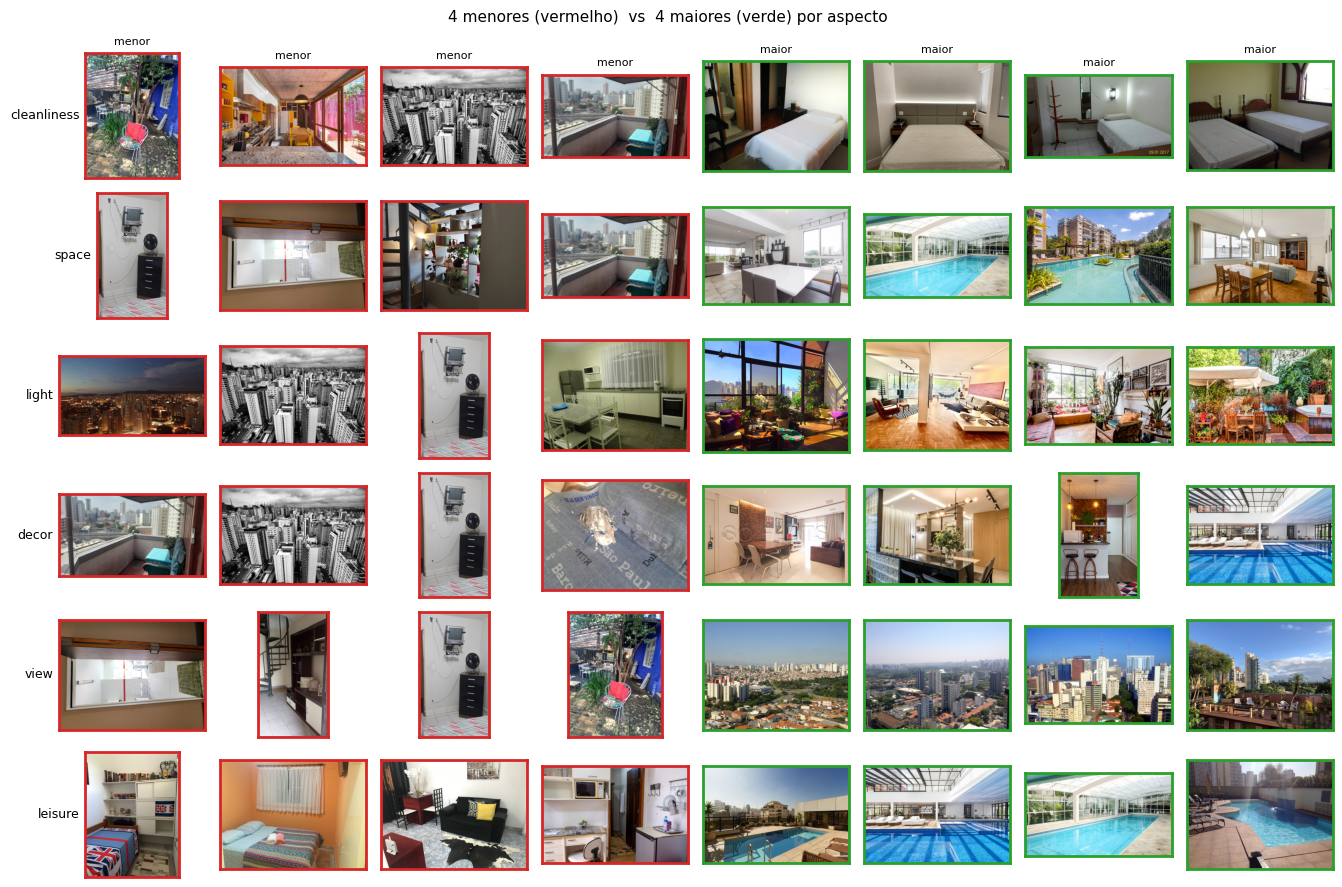

In [12]:
import matplotlib.pyplot as plt

N = 4
aspects = list(ASPECTS)
fig, axes = plt.subplots(len(aspects), N * 2, figsize=(N * 2 * 1.7, len(aspects) * 1.5))

for r, asp in enumerate(aspects):
    s   = img.sort_values(f"img_{asp}")
    sel = list(s.head(N).id) + list(s.tail(N).id[::-1])
    for c, lid in enumerate(sel):
        ax = axes[r, c]
        ax.imshow(Image.open(IMG_DIR / f"{lid}.jpg"))
        ax.set_xticks([]); ax.set_yticks([])
        if c == 0:
            ax.set_ylabel(asp, fontsize=9, rotation=0, ha="right", va="center")
        if r == 0:
            ax.set_title("menor" if c < N else "maior", fontsize=8)
        for sp in ax.spines.values():
            sp.set_color("tab:red" if c < N else "tab:green"); sp.set_linewidth(2)

plt.suptitle("4 menores (vermelho)  vs  4 maiores (verde) por aspecto", fontsize=11)
plt.tight_layout()
plt.savefig("../outputs/clip_sanity_check.png", dpi=110, bbox_inches="tight")
plt.show()